In [1]:
import os
import shutil
from pathlib import Path
from PIL import ImageFile
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_curve, auc
from sklearn.preprocessing import label_binarize
import warnings
from collections import Counter

warnings.filterwarnings('ignore')
ImageFile.LOAD_TRUNCATED_IMAGES = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [2]:
input_dir = Path("/kaggle/input")
unified_dir = Path("/tmp/disaster_data")

if unified_dir.exists():
    shutil.rmtree(unified_dir)
unified_dir.mkdir(parents=True, exist_ok=True)

base_path = next((p.parent for p in input_dir.rglob("disaster_dataset") if p.is_dir() and (p / "disaster_dataset").exists()), None)

# Copy the classes into a unified directory
nested_dir = base_path / "disaster_dataset" / "disaster_dataset"
for folder in nested_dir.iterdir():
    if folder.is_dir():
        shutil.copytree(folder, unified_dir / folder.name)

eq_dir = base_path / "earthquake"
if not eq_dir.exists():
    eq_dir = base_path / "disaster_dataset" / "earthquake"
if eq_dir.exists():
    shutil.copytree(eq_dir, unified_dir / "Earthquake")

# Data Augmentation & Loading
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

full_dataset = datasets.ImageFolder(root=str(unified_dir), transform=train_transform)
classes = full_dataset.classes
num_classes = len(classes)

torch.manual_seed(42)
train_size = int(0.8 * len(full_dataset))
test_size = len(full_dataset) - train_size
train_set, test_set = random_split(full_dataset, [train_size, test_size])
test_set.dataset.transform = test_transform

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

print(f"Dataset ready! Found {num_classes} classes: {classes}")

# Extract exact labels present in the test split
test_targets = [full_dataset.targets[i] for i in test_set.indices]
counts = Counter(test_targets)

for idx, class_name in enumerate(classes):
    print(f"{class_name}: Test = {counts[idx]}")

Dataset ready! Found 6 classes: ['Earthquake', 'fire', 'flood', 'landslide', 'normal', 'smoke']
Earthquake: Test = 214
fire: Test = 489
flood: Test = 536
landslide: Test = 59
normal: Test = 447
smoke: Test = 72


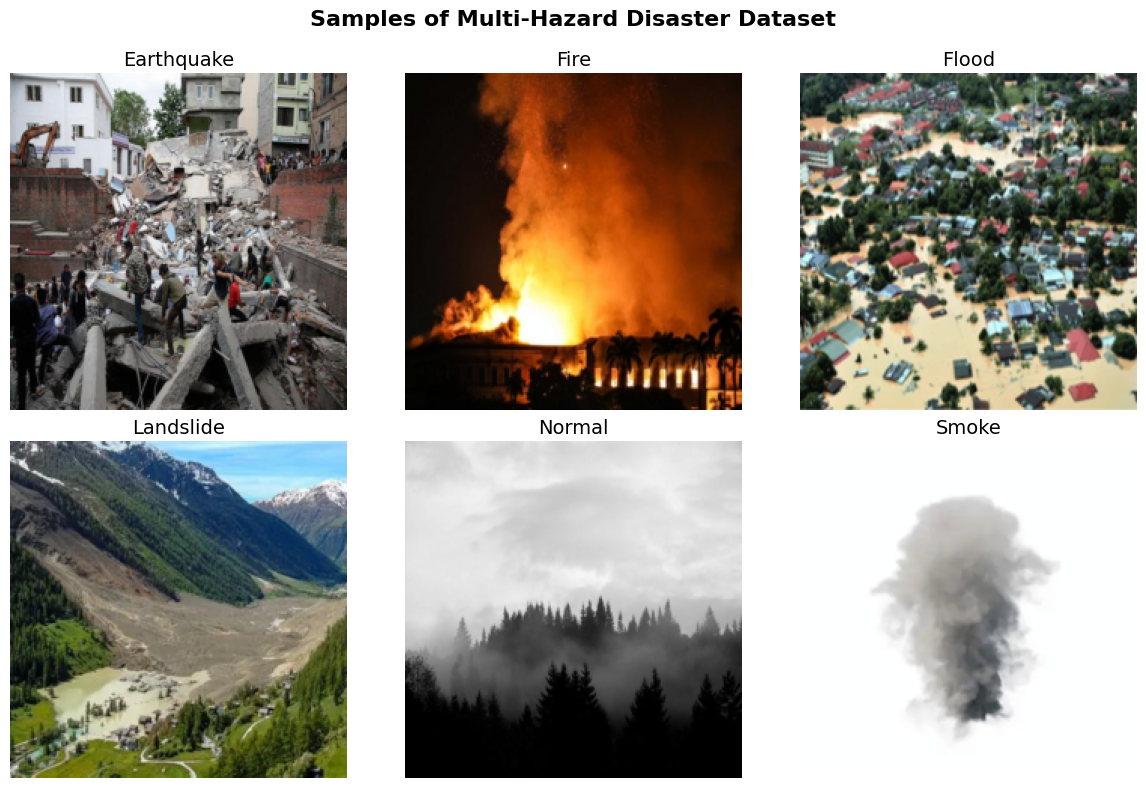

In [3]:
# Create a 2x3 grid for the 6 classes
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
fig.suptitle("Samples of Multi-Hazard Disaster Dataset", fontsize=16, fontweight='bold')
axes = axes.flatten()

class_found = {c: False for c in classes}
images_plotted = 0

# Scan the dataset to find one image per class
for img, label in full_dataset:
    class_name = classes[label]
    if not class_found[class_name]:
        # Un-normalize the image so it looks normal to the human eye
        img = img.numpy().transpose((1, 2, 0))
        mean = np.array([0.485, 0.456, 0.406])
        std = np.array([0.229, 0.224, 0.225])
        img = std * img + mean
        img = np.clip(img, 0, 1)
        
        # Plot the image
        axes[images_plotted].imshow(img)
        axes[images_plotted].set_title(class_name.capitalize(), fontsize=14)
        axes[images_plotted].axis('off')
        
        class_found[class_name] = True
        images_plotted += 1
        
    if images_plotted == 6:
        break

plt.tight_layout()
plt.subplots_adjust(top=0.90)
plt.show()

In [4]:
def train_and_evaluate(model, model_name, epochs=5):
    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    print(f"\n{'='*55}")
    print(f"   STARTING 5-EPOCH TRAINING: {model_name.upper()}")
    print(f"{'='*55}")

    # Dictionary to track metrics for the curves
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

    # ---------------------------------------------------------
    # 1. EPOCH LOOP (Train & Evaluate per epoch)
    # ---------------------------------------------------------
    for epoch in range(epochs):
        # --- TRAINING PASS ---
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct_train += torch.sum(preds == labels).item()
            total_train += labels.size(0)

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = (correct_train / total_train) * 100

        # --- TESTING PASS ---
        model.eval()
        val_loss, correct_test, total_test = 0.0, 0, 0
        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, preds = torch.max(outputs, 1)
                correct_test += torch.sum(preds == labels).item()
                total_test += labels.size(0)

        epoch_test_loss = val_loss / total_test
        epoch_test_acc = (correct_test / total_test) * 100

        # Save metrics for plotting
        history['train_loss'].append(epoch_train_loss)
        history['train_acc'].append(epoch_train_acc)
        history['test_loss'].append(epoch_test_loss)
        history['test_acc'].append(epoch_test_acc)

        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_acc:.2f}% | Test Loss: {epoch_test_loss:.4f}, Test Acc: {epoch_test_acc:.2f}%")

    # ---------------------------------------------------------
    # 2. PLOT ACCURACY AND LOSS CURVES
    # ---------------------------------------------------------
    epochs_range = range(1, epochs + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Loss Curve
    ax1.plot(epochs_range, history['train_loss'], label='Train Loss', marker='o', lw=2)
    ax1.plot(epochs_range, history['test_loss'], label='Test Loss', marker='o', lw=2)
    ax1.set_title(f'{model_name} - Loss Curve')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(alpha=0.3)

    # Accuracy Curve
    ax2.plot(epochs_range, history['train_acc'], label='Train Accuracy', marker='o', lw=2)
    ax2.plot(epochs_range, history['test_acc'], label='Test Accuracy', marker='o', lw=2)
    ax2.set_title(f'{model_name} - Accuracy Curve')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy (%)')
    ax2.legend()
    ax2.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------------
    # 3. CONFUSION MATRICES (TRAIN & TEST)
    # ---------------------------------------------------------
    def plot_cm(loader, title_suffix):
        model.eval()
        all_preds, all_labels = [], []
        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                outputs = model(images)
                _, preds = torch.max(outputs, 1)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.numpy())

        cm = confusion_matrix(all_labels, all_preds)
        cm_norm = cm.astype('float') / (cm.sum(axis=1)[:, np.newaxis] + 1e-10)
        
        plt.figure(figsize=(7, 5))
        sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', xticklabels=classes, yticklabels=classes)
        plt.title(f"{model_name} - {title_suffix}")
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.tight_layout()
        plt.show()
        return all_labels, all_preds

    print("\nPlotting Confusion Matrices...")
    plot_cm(train_loader, "Final TRAINING Set")
    test_labels, test_preds = plot_cm(test_loader, "Final TESTING Set")

    # ---------------------------------------------------------
    # 4. FINAL METRICS & ROC CURVE
    # ---------------------------------------------------------
    all_probs = []
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            outputs = model(images)
            probs = torch.softmax(outputs, dim=1)
            all_probs.extend(probs.cpu().numpy())
    all_probs = np.array(all_probs)

    acc = accuracy_score(test_labels, test_preds)
    precision = precision_score(test_labels, test_preds, average='macro', zero_division=0)
    recall = recall_score(test_labels, test_preds, average='macro', zero_division=0)
    f1 = f1_score(test_labels, test_preds, average='macro', zero_division=0)

    print(f"\n--- {model_name.upper()} FINAL METRICS ---")
    print(f"Test Accuracy: {acc * 100:.2f}%")
    print(f"Precision:     {precision:.4f}")
    print(f"Recall:        {recall:.4f}")
    print(f"F1-Score:      {f1:.4f}")

    binarized_labels = label_binarize(test_labels, classes=[i for i in range(num_classes)])
    plt.figure(figsize=(9, 7))
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(binarized_labels[:, i], all_probs[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, lw=2, label=f'{classes[i]} (AUC = {roc_auc:.2f})')

    plt.plot([0, 1], [0, 1], 'k--', lw=2, label='Random Chance')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Multi-Class ROC Curve — {model_name}')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

Loading VGG-16...
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 217MB/s]



   STARTING 5-EPOCH TRAINING: VGG-16
Epoch [1/5] | Train Loss: 0.3629, Train Acc: 88.05% | Test Loss: 0.2384, Test Acc: 92.07%
Epoch [2/5] | Train Loss: 0.1450, Train Acc: 95.35% | Test Loss: 0.1556, Test Acc: 95.60%
Epoch [3/5] | Train Loss: 0.1083, Train Acc: 96.60% | Test Loss: 0.2301, Test Acc: 93.40%
Epoch [4/5] | Train Loss: 0.0729, Train Acc: 97.73% | Test Loss: 0.1676, Test Acc: 95.87%
Epoch [5/5] | Train Loss: 0.0677, Train Acc: 97.85% | Test Loss: 0.2642, Test Acc: 94.61%


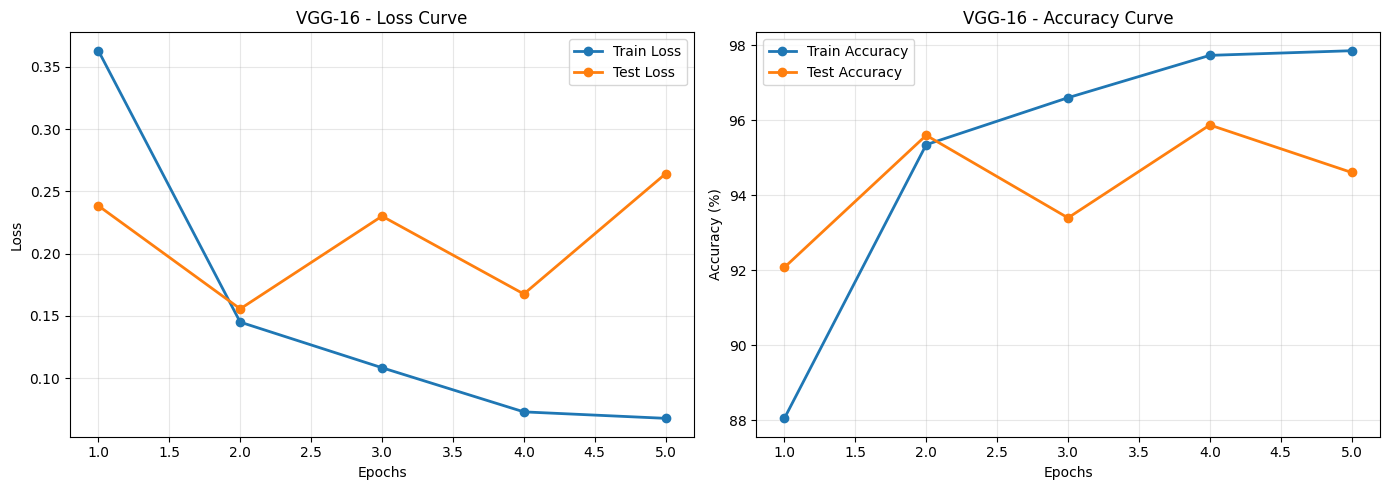


Plotting Confusion Matrices...


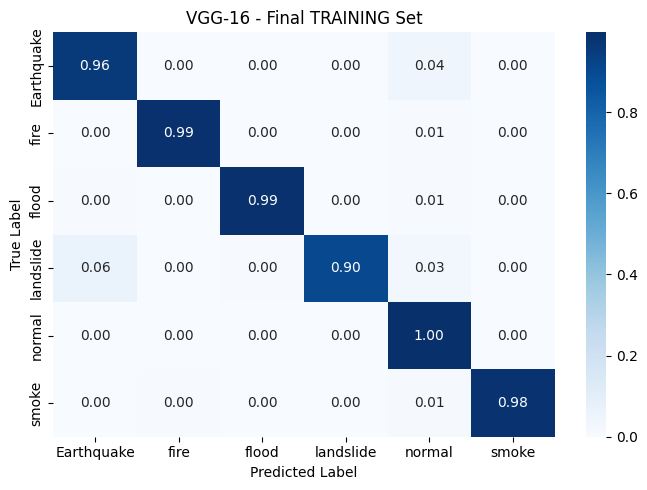

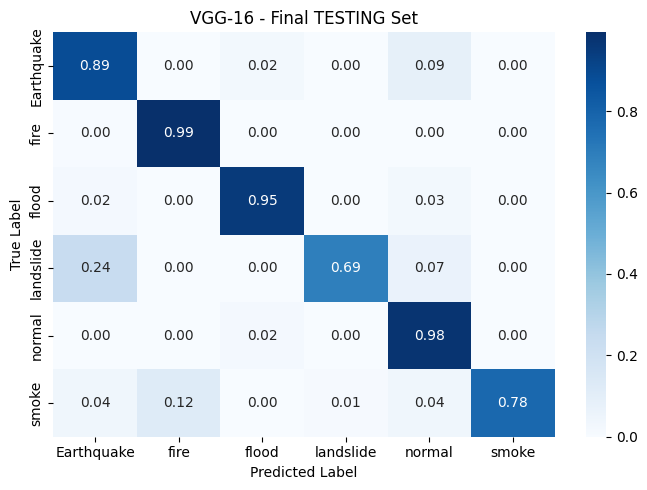


--- VGG-16 FINAL METRICS ---
Test Accuracy: 94.61%
Precision:     0.9467
Recall:        0.8802
F1-Score:      0.9075


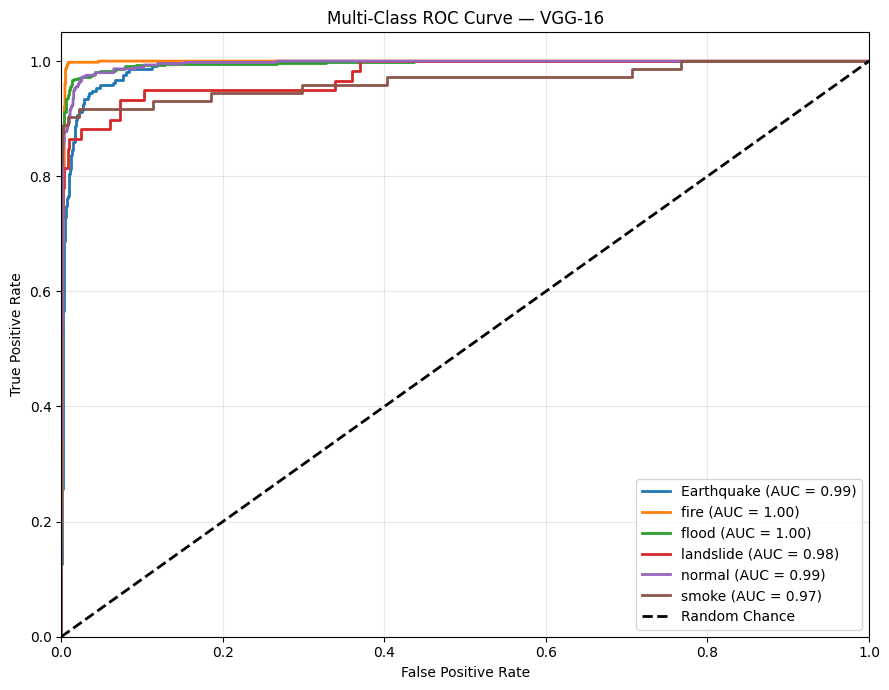

In [5]:
# ==========================================
# VGG-16 STANDARD TRAINING
# ==========================================
print("Loading VGG-16...")
vgg = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

num_features = vgg.classifier[6].in_features
vgg.classifier[6] = nn.Linear(num_features, num_classes)
vgg = vgg.to(device)

# Execute standard 5-epoch training 
train_and_evaluate(vgg, "VGG-16", epochs=5)